(mmm_multi_arm_geolift_calibration)=
# MMM Calibration with Multi-Arm Geo Lift Tests

A retailer reallocates search spend across 48 synthetic state markets: 16 increase spend, 16 decrease it, and 16 remain unchanged. The delivered changes sum to zero, but their revenue effects need not. We estimate each treated market's signed effect with CausalPy and use those estimates to calibrate a hierarchical MMM.

This extends {ref}`mmm_geolift_calibration` and assumes familiarity with {ref}`mmm_multidimensional_example` and [CausalPy's up/down/control example](https://causalpy.readthedocs.io/en/latest/notebooks/up-down-control-geolift-pymc.html). Allocation is supplied; geographic balancing and spillover analysis are outside this example.

| Arm | Markets | Planned search change per market | Delivered change | Expected effect |
|---|---:|---:|---:|---|
| Up | 16 | +8,000 USD/week | +7,200 USD/week | Positive |
| Down | 16 | −8,000 USD/week | −7,200 USD/week | Negative |
| Control | 16 | 0 | 0 | Zero |

State labels follow the [Census state code reference](https://cdn.www.census.gov/library/reference/code-lists/ansi/ansi-codes-for-states.html). All sizes, assignments, spend, parameters, and revenue are synthetic; these are state markets, not DMAs.

## Setup and a compatible data-generating process

We use logistic response curves with geo-specific parameters, correlated historical channels, and no carryover. Common sine/cosine controls represent seasonality with shared coefficients. Both MMMs use fixed 100,000 USD scales, so the simulated parameters and fitted curves have the same interpretation. Use the repo's development environment with its `docs` and `test` extras. The optional `docs` dependencies include CausalPy 1.0.0rc1 or newer for the exporter and Nutpie 0.16.11 or newer for low-rank adaptation:

```bash
uv sync --locked --extra docs --extra test
```

In [1]:
import logging
import time

import arviz as az
import causalpy as cp
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.xtensor as ptx
import xarray as xr
from IPython.display import display
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from pymc_extras.prior import Prior

from pymc_marketing.mmm import MMM, LogisticSaturation, NoAdstock
from pymc_marketing.mmm.scaling import FixedScaling, Scaling
from pymc_marketing.mmm.transformers import logistic_saturation

%config InlineBackend.figure_format = "retina"
logging.getLogger("pymc").setLevel(logging.WARNING)
FIG_WIDTH, FIG_HEIGHT = 10, 3.5
COLOR_UP, COLOR_DOWN, COLOR_CONTROL = "#0072B2", "#D55E00", "#777777"
CHANNEL_COLORS = {"search": "#0072B2", "display": "#009E73"}
ARM_COLORS = {"up": COLOR_UP, "down": COLOR_DOWN, "control": COLOR_CONTROL}
plt.rcParams.update(
    {
        "figure.figsize": (FIG_WIDTH, FIG_HEIGHT),
        "font.size": 12,
        "axes.labelsize": 12,
        "xtick.labelsize": 11,
        "ytick.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.constrained_layout.use": True,
    }
)
USD = StrMethodFormatter("${x:,.0f}")
SEED = sum(map(ord, "Signed multi-arm geo calibration"))
streams = np.random.SeedSequence(SEED).spawn(5)
rng_parameters, rng_spend, rng_history, rng_experiment, rng_assignment = [
    np.random.default_rng(s) for s in streams
]
SCALE = 100_000.0
channels = ["search", "display"]
started = time.perf_counter()

In [2]:
geos = (
    "AL AZ AR CA CO CT DE FL GA ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT "
    "NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY"
).split()
geos = sorted(geos)
# Assignment is independent of response parameters. Control levels span the treated levels.
assigned = rng_assignment.permutation(geos).tolist()
arm_size = len(geos) // 3
arms = {
    arm: sorted(assigned[i * arm_size : (i + 1) * arm_size])
    for i, arm in enumerate(["up", "down", "control"])
}
geo_arm = {g: arm for arm, members in arms.items() for g in members}
G = len(geos)
dates = pd.date_range("2022-01-03", periods=144, freq="W-MON")
train_dates, estimation_dates = dates[:104], dates[104:]
experiment_start, experiment_end = dates[136], dates[-1]
window = estimation_dates[estimation_dates >= experiment_start]
true_lam = rng_parameters.lognormal(np.log([4.0, 3.0]), 0.12, (G, 2))
true_beta = rng_parameters.lognormal(np.log([0.6, 0.5]), 0.12, (G, 2))
true_intercept = rng_parameters.uniform(0.50, 0.70, G)
true_intercept[[geos.index(g) for g in arms["control"]]] = np.linspace(
    0.20, 1.00, arm_size
)
base_spend = rng_spend.uniform(32_000, 48_000, (G, 2))
shared_spend = rng_spend.uniform(0.65, 1.35, (104, G, 1))
historical_spend = base_spend[None, :, :] * shared_spend + rng_spend.normal(
    0, 1_500, (104, G, 2)
)
baseline = np.broadcast_to(base_spend, (40, G, 2)).copy()
planned = baseline.copy()
for arm, sign in [("up", 1), ("down", -1)]:
    planned[32:, [geos.index(g) for g in arms[arm]], 0] += sign * 8_000
realized = baseline + 0.9 * (planned - baseline)
season_controls = np.column_stack(
    [np.sin(2 * np.pi * np.arange(144) / 52), np.cos(2 * np.pi * np.arange(144) / 52)]
)
true_gamma = np.array([0.06, 0.03])


def media_response(spend):
    x = ptx.as_xtensor(spend / SCALE, dims=("time", "geo", "channel"))
    lam = ptx.as_xtensor(true_lam, dims=("geo", "channel"))
    saturated = (
        logistic_saturation(x, lam=lam).transpose("time", "geo", "channel").eval()
    )
    return (true_beta * saturated).sum(axis=-1) * SCALE


mu_history = SCALE * (
    true_intercept + season_controls[:104] @ true_gamma[:, None]
) + media_response(historical_spend)
mu_baseline = SCALE * (
    true_intercept + season_controls[104:] @ true_gamma[:, None]
) + media_response(baseline)
mu_experiment = SCALE * (
    true_intercept + season_controls[104:] @ true_gamma[:, None]
) + media_response(realized)
y_history = mu_history + rng_history.normal(0, 1_000, mu_history.shape)
y_experiment = mu_experiment + rng_experiment.normal(0, 1_000, mu_experiment.shape)
true_lift = pd.Series((mu_experiment - mu_baseline)[32:].mean(axis=0), index=geos)


def long_features(spend, selected_dates, controls):
    frame = pd.DataFrame(spend.reshape(-1, 2), columns=channels)
    frame["date"] = np.repeat(selected_dates, G)
    frame["geo"] = np.tile(geos, len(selected_dates))
    frame[["annual_sin", "annual_cos"]] = np.repeat(controls, G, axis=0)
    return frame


X_train = long_features(historical_spend, train_dates, season_controls[:104])
y_train = pd.Series(y_history.ravel(), name="revenue")
experiment_revenue = pd.DataFrame(y_experiment, index=estimation_dates, columns=geos)
spend_columns = pd.MultiIndex.from_product([geos, channels], names=["geo", "channel"])
spend_baseline = pd.DataFrame(
    baseline.reshape(40, -1), index=estimation_dates, columns=spend_columns
)
spend_realized = pd.DataFrame(
    realized.reshape(40, -1), index=estimation_dates, columns=spend_columns
)
for frame in (experiment_revenue, spend_baseline, spend_realized):
    frame.attrs["unit"] = "USD/week"
np.testing.assert_equal(len(set(geos)), 48)
np.testing.assert_equal([len(arms[a]) for a in arms], [16, 16, 16])
np.testing.assert_equal(len(train_dates.intersection(estimation_dates)), 0)
np.testing.assert_array_equal(realized[:, :, 1], baseline[:, :, 1])
np.testing.assert_array_equal(
    realized[:, [geos.index(g) for g in arms["control"]]],
    baseline[:, [geos.index(g) for g in arms["control"]]],
)
for values in (historical_spend, baseline, realized, y_history, y_experiment):
    if not np.isfinite(values).all() or values.min() <= 0:
        raise ValueError("The simulation must have finite positive spend and revenue.")

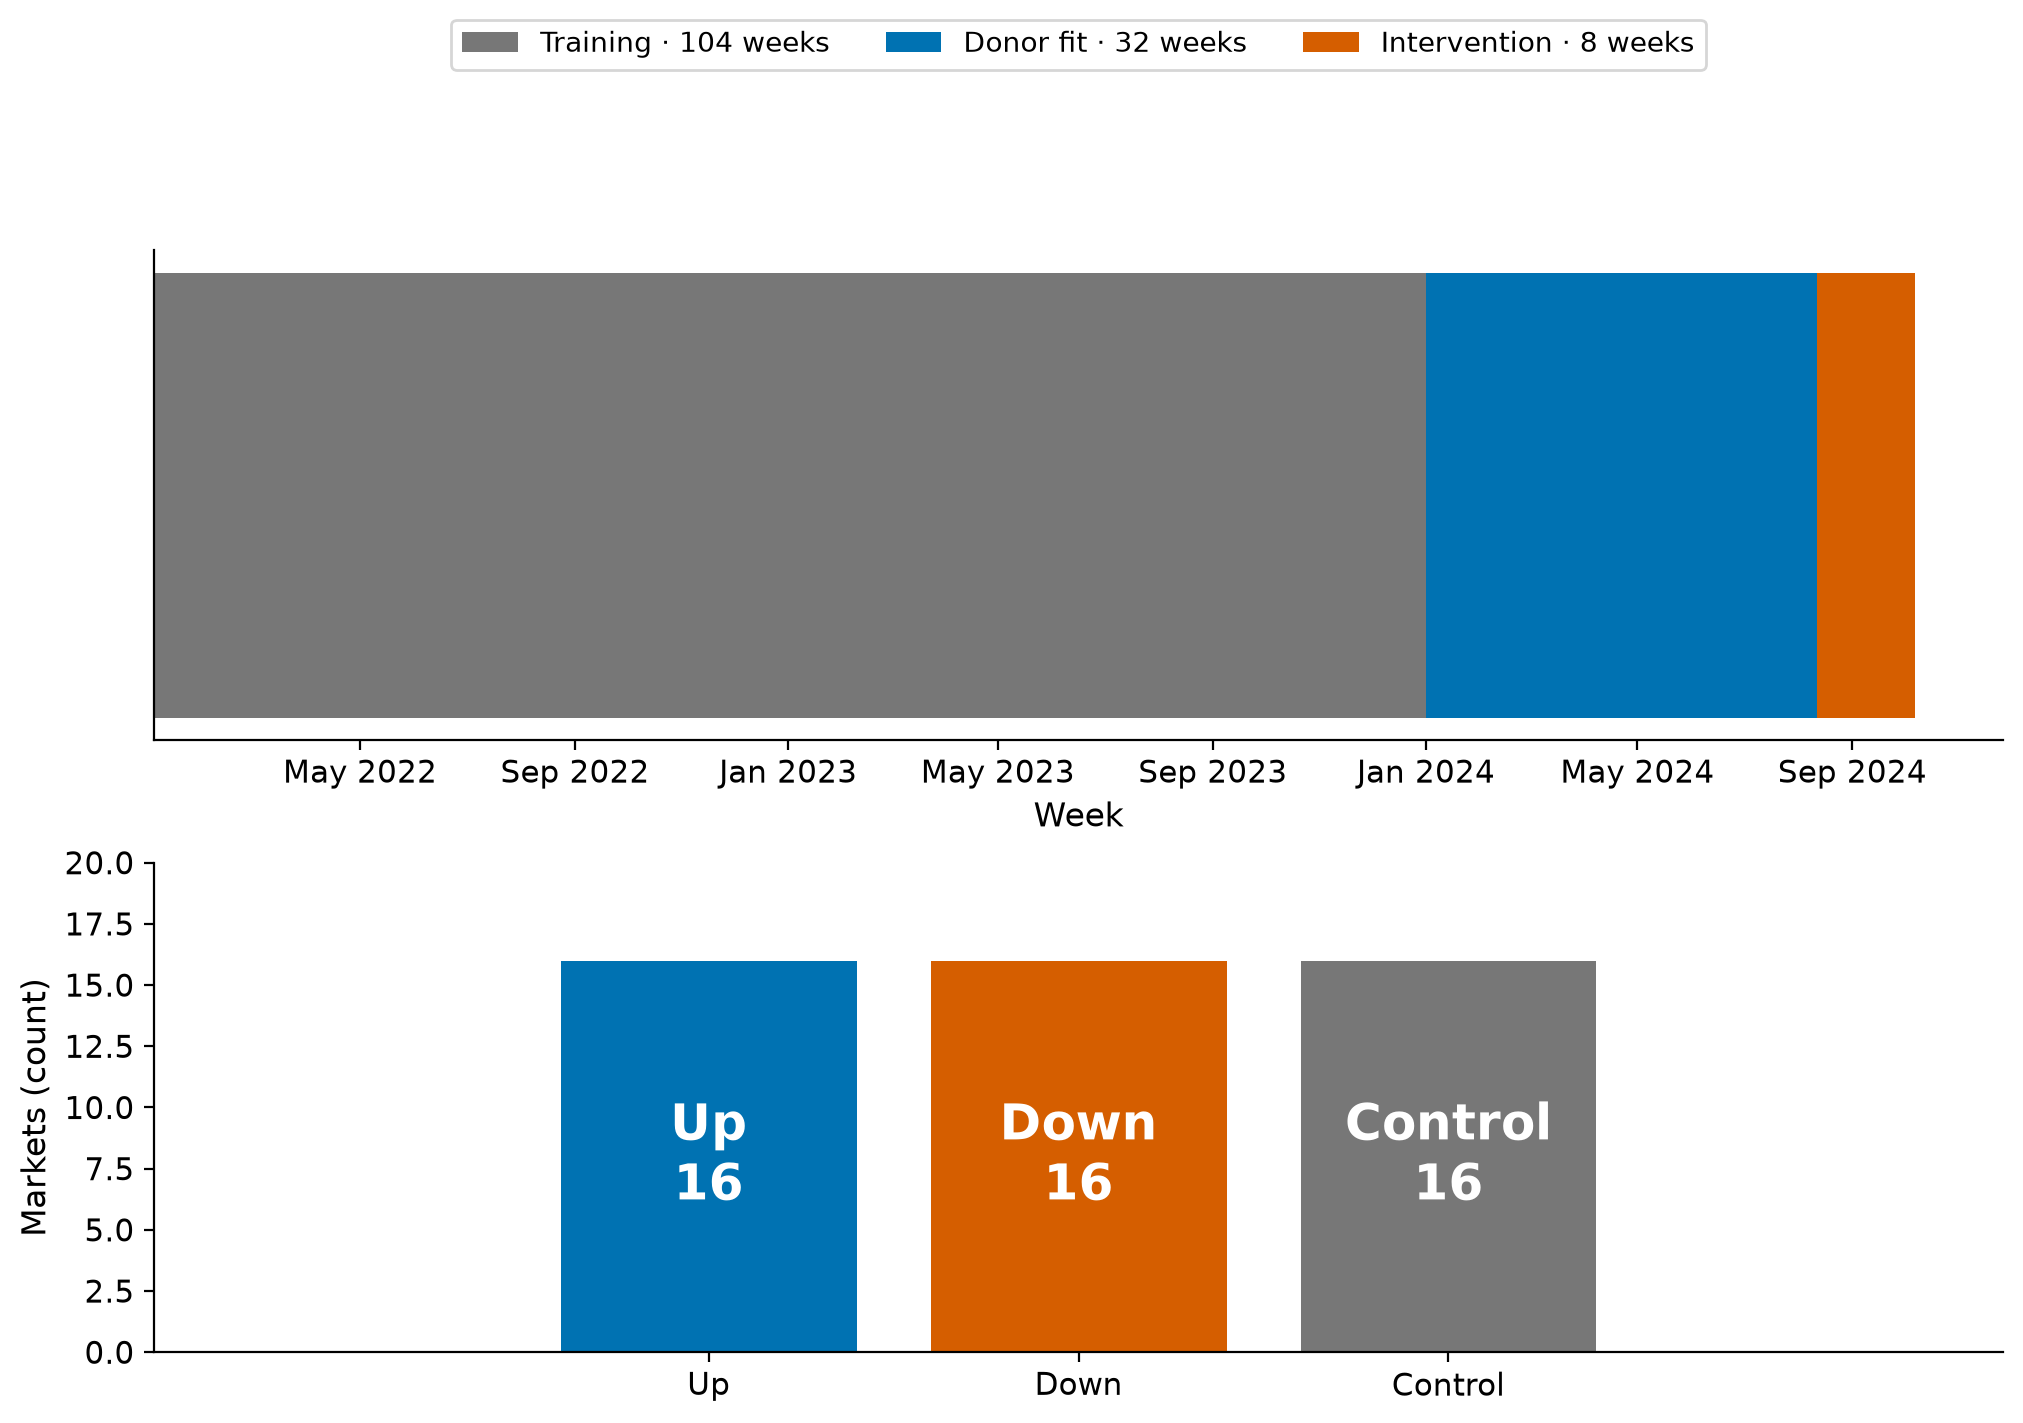

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(FIG_WIDTH, FIG_HEIGHT * 2))
for label, start, end, color in [
    ("Training · 104 weeks", dates[0], dates[103], COLOR_CONTROL),
    ("Donor fit · 32 weeks", dates[104], dates[135], COLOR_UP),
    ("Intervention · 8 weeks", dates[136], dates[-1], COLOR_DOWN),
]:
    axes[0].barh(
        0, end - start + pd.Timedelta(weeks=1), left=start, color=color, label=label
    )
axes[0].set_yticks([])
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.5), ncol=3, fontsize=10)
axes[0].set_xlabel("Week")
arm_positions = [0.3, 0.5, 0.7]
axes[1].bar(
    arm_positions,
    [len(v) for v in arms.values()],
    width=0.16,
    color=[ARM_COLORS[a] for a in arms],
)
for position, arm in zip(arm_positions, arms, strict=True):
    axes[1].text(
        position,
        8,
        f"{arm.title()}\n{len(arms[arm])}",
        ha="center",
        va="center",
        color="white",
        fontsize=18,
        fontweight="bold",
    )
axes[1].set_xticks(arm_positions, [a.title() for a in arms])
axes[1].set(ylabel="Markets (count)", ylim=(0, 20), xlim=(0, 1))
plt.show()

**Caption:** Disjoint weekly data partitions and market counts. The MMM sees only historical training outcomes; CausalPy sees the reserved counterfactual-fit and intervention periods.

Unlike the predecessor, we remove carryover and keep experimental baseline spend constant. This makes the scalar saturation contrast exact. Controls span the treated revenue levels by construction; the allocation is illustrative, not an optimization of real markets.

In [4]:
historical_correlations = (
    X_train.groupby("geo")[channels].corr().loc[(slice(None), "search"), "display"]
)
display(historical_correlations.describe().to_frame("Historical channel correlation"))
display(
    pd.DataFrame(
        {"weeks": [104, 32, 8], "markets": [G, G, G]},
        index=["MMM training", "Counterfactual fit", "Intervention"],
    )
)

,Historical channel correlation
count,48.000000
mean,0.966045
std,0.008139
min,0.943546
25%,0.961867
50%,0.966647
75%,0.973142
max,0.980141


,weeks,markets
MMM training,104,48
Counterfactual fit,32,48
Intervention,8,48


The historical channels remain strongly correlated within each market. Independent spend variation of 1,500 USD/week avoids making them nearly identical, while leaving substantial tradeoffs between their response curves. The reserved experimental panel holds display unchanged and isolates search changes.

## A spend-neutral intervention

Equal planned increases and decreases receive the same 90% delivery fraction. We verify neutrality from the delivered panel rather than assuming planned spend was delivered. Each geo retains its own baseline and signed change.

,planned,delivered
up,"$128,000","$115,200"
down,"$-128,000","$-115,200"
control,$0,$0
net,$0,$0


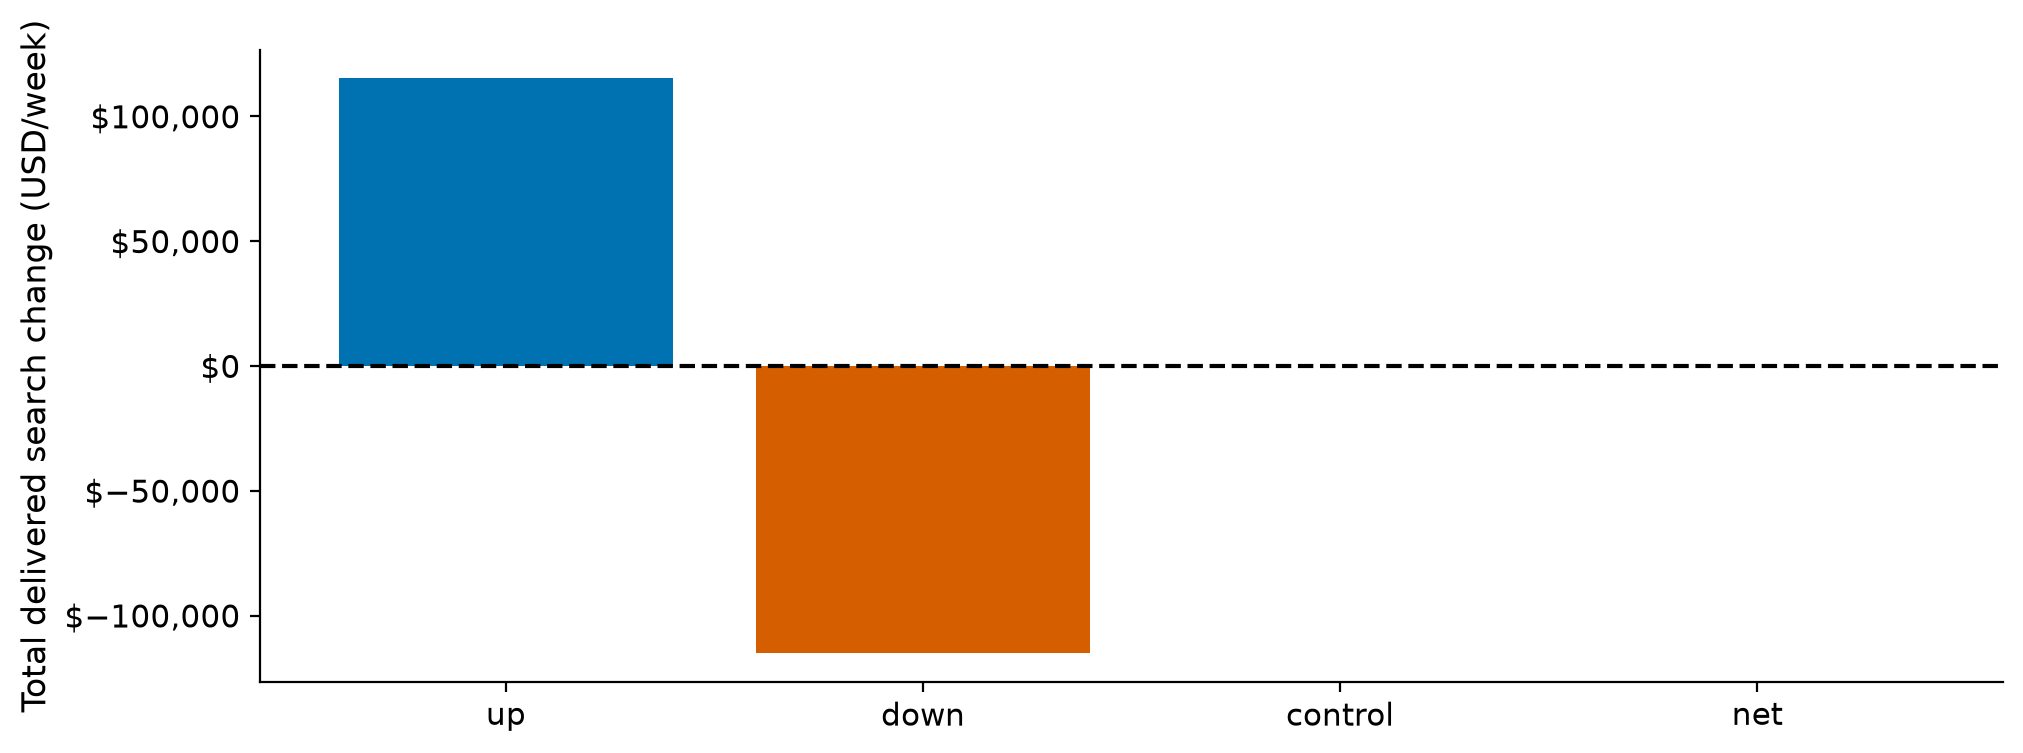

In [5]:
accounting = pd.DataFrame(index=["up", "down", "control"])
for label, panel in [("planned", planned), ("delivered", realized)]:
    accounting[label] = [
        (panel - baseline)[32:, [geos.index(g) for g in arms[a]], 0].sum(axis=1).mean()
        for a in accounting.index
    ]
accounting.loc["net"] = accounting.sum()
for panel in (planned, realized):
    np.testing.assert_allclose((panel - baseline)[32:, :, 0].sum(axis=1), 0, atol=1e-8)
np.testing.assert_allclose(np.ptp(baseline[32:], axis=0), 0, atol=1e-8)
np.testing.assert_allclose(np.ptp((realized - baseline)[32:], axis=0), 0, atol=1e-8)
representatives = {
    a: sorted(arms[a], key=lambda g: base_spend[geos.index(g), 0])[arm_size // 2]
    for a in arms
}
display(accounting.style.format("${:,.0f}"))
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT))
ax.bar(
    accounting.index,
    accounting.delivered,
    color=[COLOR_UP, COLOR_DOWN, COLOR_CONTROL, "black"],
)
ax.axhline(0, color="black", linestyle="--")
ax.set_ylabel("Total delivered search change (USD/week)")
ax.yaxis.set_major_formatter(USD)
plt.show()

**Caption:** Delivered weekly search changes summed across markets in each arm and across the experiment. Planned and delivered net changes are zero to an absolute tolerance of 10⁻⁸ USD/week.

Spend neutrality does not imply outcome neutrality: geos differ in baseline spend and response curves, and the downward and upward changes traverse different portions of those curves. Representative markets below are selected by median baseline search spend before inspecting estimated effects.

## Estimate signed lift with CausalPy

One joint fit uses only unchanged controls as donors. Neither active arm supplies donors to the other. Identification still requires adequate pre-period fit, no spillovers, and no concurrent market-specific changes correlated with assignment. Two chains with 1,000 retained draws each support diagnostics; progress bars are disabled to keep the saved page readable.

In [6]:
sc_fit_kwargs = dict(
    tune=1_000,
    draws=1_000,
    chains=2,
    cores=2,
    target_accept=0.95,
    nuts_sampler="nutpie",
    random_seed=SEED + 10,
    progressbar=False,
)
mmm_fit_kwargs = dict(
    tune=2_000,
    draws=2_000,
    chains=2,
    cores=2,
    nuts_sampler="nutpie",
    random_seed=SEED + 20,
    progressbar=False,
    nuts={
        "target_accept": 0.95,
        "adaptation": "low_rank",
        "mass_matrix_eigval_cutoff": 3,
    },
)
result = cp.UpDownGeoLift(
    experiment_revenue,
    treatment_time=experiment_start,
    arms=arms,
    model=cp.pymc_models.SoftmaxWeightedSumFitter(sample_kwargs=sc_fit_kwargs),
).fit()

In [7]:
lift_rows = result.to_mmm_lift(
    spend_baseline=spend_baseline,
    spend_realized=spend_realized,
    channel="search",
    spend_unit="USD/week",
    outcome_unit="USD/week",
    start=experiment_start,
    end=experiment_end,
)
np.testing.assert_equal(len(lift_rows), 32)
np.testing.assert_equal(set(lift_rows.geo), set(arms["up"] + arms["down"]))
if (
    not np.isfinite(lift_rows[["delta_y", "sigma"]]).all().all()
    or not (lift_rows.sigma > 0).all()
):
    raise ValueError("Exported effects and uncertainties must be valid.")
np.testing.assert_array_equal(np.sign(lift_rows.delta_x), np.sign(lift_rows.delta_y))
display(
    lift_rows[["geo", "arm", "channel", "x", "delta_x", "delta_y", "sigma"]]
    .groupby("arm", sort=False)
    .head(2)
    .style.format({c: "{:,.1f}" for c in ["x", "delta_x", "delta_y", "sigma"]})
)
display(
    lift_rows[
        ["window_start", "window_end", "n_periods", "spend_unit", "outcome_unit"]
    ].drop_duplicates()
)

,geo,arm,channel,x,delta_x,delta_y,sigma
0,AZ,up,search,"42,195.5","7,200.0","3,508.3",204.1
1,DE,up,search,"47,177.6","7,200.0","3,943.5",216.0
16,AL,down,search,"40,227.9","-7,200.0","-5,034.7",190.3
17,CA,down,search,"36,863.6","-7,200.0","-4,892.5",169.2


,window_start,window_end,n_periods,spend_unit,outcome_unit
0,2024-08-12,2024-09-30,8,USD/week,USD/week


These are fitted estimates, not the planted effects. `x` is that geo's mean business-as-usual search spend; `delta_x` is delivered minus business-as-usual spend. Thus `x + delta_x` is delivered spend, below baseline for a down geo and above it for an up geo. `delta_y` is the posterior mean of mean weekly impact. `sigma` is the posterior SD of that time-averaged impact: do not divide it by √8 again. All four quantities are in USD/week.

The exporter currently rejects estimates whose sign disagrees with delivered spend. That is an exporter restriction; the MMM's signed Normal likelihood can accept noisy discordant observations. We preserve all 32 exported geos without flipping, clipping, or replacing estimates.

In [8]:
pre_residual = result.result.impact_pre
pre_rmse = np.sqrt((pre_residual.mean(["chain", "draw"]) ** 2).mean("obs_ind"))
pre_table = pre_rmse.to_series().rename("Pre-fit RMSE (USD/week)").to_frame()
pre_table["arm"] = [geo_arm[g] for g in pre_table.index]
display(
    pre_table.sort_values(["arm", "Pre-fit RMSE (USD/week)"]).style.format(
        {"Pre-fit RMSE (USD/week)": "${:,.0f}"}
    )
)

,Pre-fit RMSE (USD/week),arm
treated_units,,
CT,$773,down
CA,$781,down
GA,$797,down
ND,$798,down
KY,$847,down
FL,$861,down
SD,$873,down
MI,$925,down
NC,$928,down


This table checks every treated market. It is an in-sample fit diagnostic, not evidence that post-intervention counterfactual assumptions hold. The next figure inspects trajectories and signed impact for the two predetermined representatives.

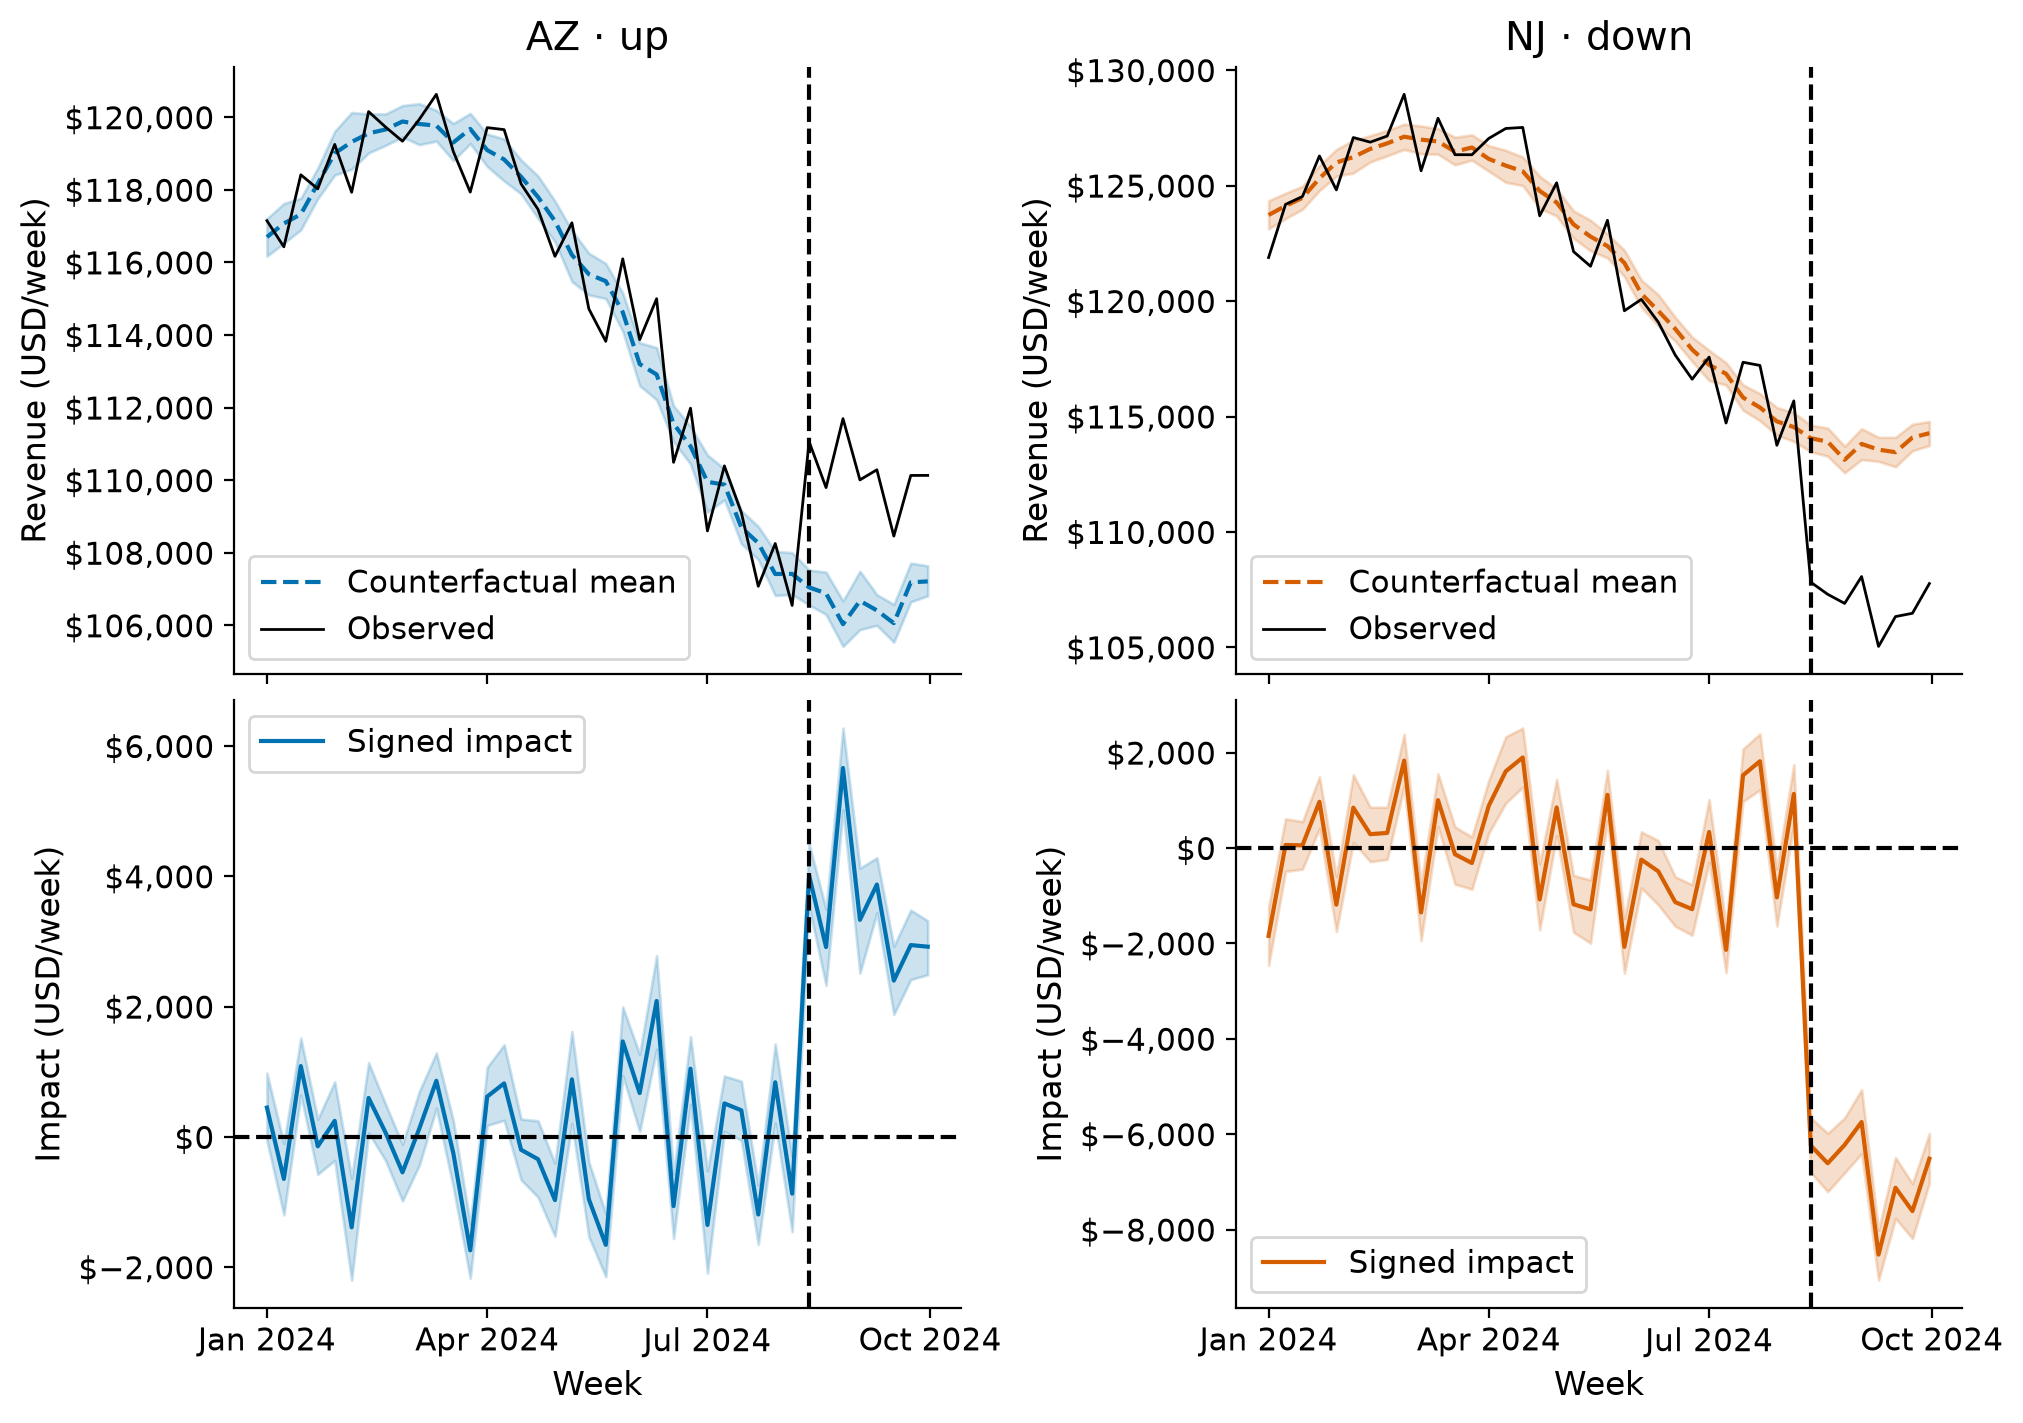

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(FIG_WIDTH, FIG_HEIGHT * 2), sharex=True)
for col, arm in enumerate(["up", "down"]):
    g = representatives[arm]
    color = ARM_COLORS[arm]
    pre = result.result.impact_pre.sel(treated_units=g)
    post = result.impact_draws.sel(treated_units=g)
    impacts = xr.concat([pre, post], dim="obs_ind").transpose(
        "chain", "draw", "obs_ind"
    )
    observed = experiment_revenue[g]
    cf = (
        xr.DataArray(
            observed.to_numpy(), dims="obs_ind", coords={"obs_ind": observed.index}
        )
        - impacts
    )
    for row, draws, label in [
        (0, cf, "Counterfactual mean"),
        (1, impacts, "Signed impact"),
    ]:
        ax = axes[row, col]
        bounds = draws.quantile([0.03, 0.97], dim=["chain", "draw"])
        ax.fill_between(
            estimation_dates,
            bounds.isel(quantile=0),
            bounds.isel(quantile=1),
            color=color,
            alpha=0.2,
        )
        ax.plot(
            estimation_dates,
            draws.mean(["chain", "draw"]),
            color=color,
            linestyle="--" if row == 0 else "-",
            label=label,
        )
        ax.axvline(experiment_start, color="black", linestyle="--")
        ax.yaxis.set_major_formatter(USD)
        ax.set_ylabel("Revenue (USD/week)" if row == 0 else "Impact (USD/week)")
        ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=4))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
        ax.legend(fontsize=11)
    axes[0, col].plot(
        estimation_dates, observed, color="black", linewidth=1, label="Observed"
    )
    axes[0, col].set_title(f"{g} · {arm}")
    axes[0, col].legend(fontsize=11)
    axes[1, col].axhline(0, color="black", linestyle="--")
    axes[1, col].set_xlabel("Week")
plt.show()

**Caption:** Observed revenue, synthetic counterfactual, and signed weekly impact for median-baseline-spend up/down geos. Bands are 94% equal-tailed posterior intervals (ETIs); the vertical dashed line marks intervention. These impact intervals condition on observed donor outcomes.

The arm table below reports mean weekly effect **per geo**, averaging aligned posterior draws across the eight intervention weeks and the 16 geos in each arm. Its units are USD/week/geo, whereas the earlier spend-accounting table reports totals across each arm. Only the separate geo-level rows enter MMM calibration.

,arm,Mean (USD/week/geo),Posterior SD,94% ETI lower,94% ETI upper
32,up,4165.6,52.4,4069.5,4266.6
33,down,-5323.0,51.6,-5420.2,-5227.0


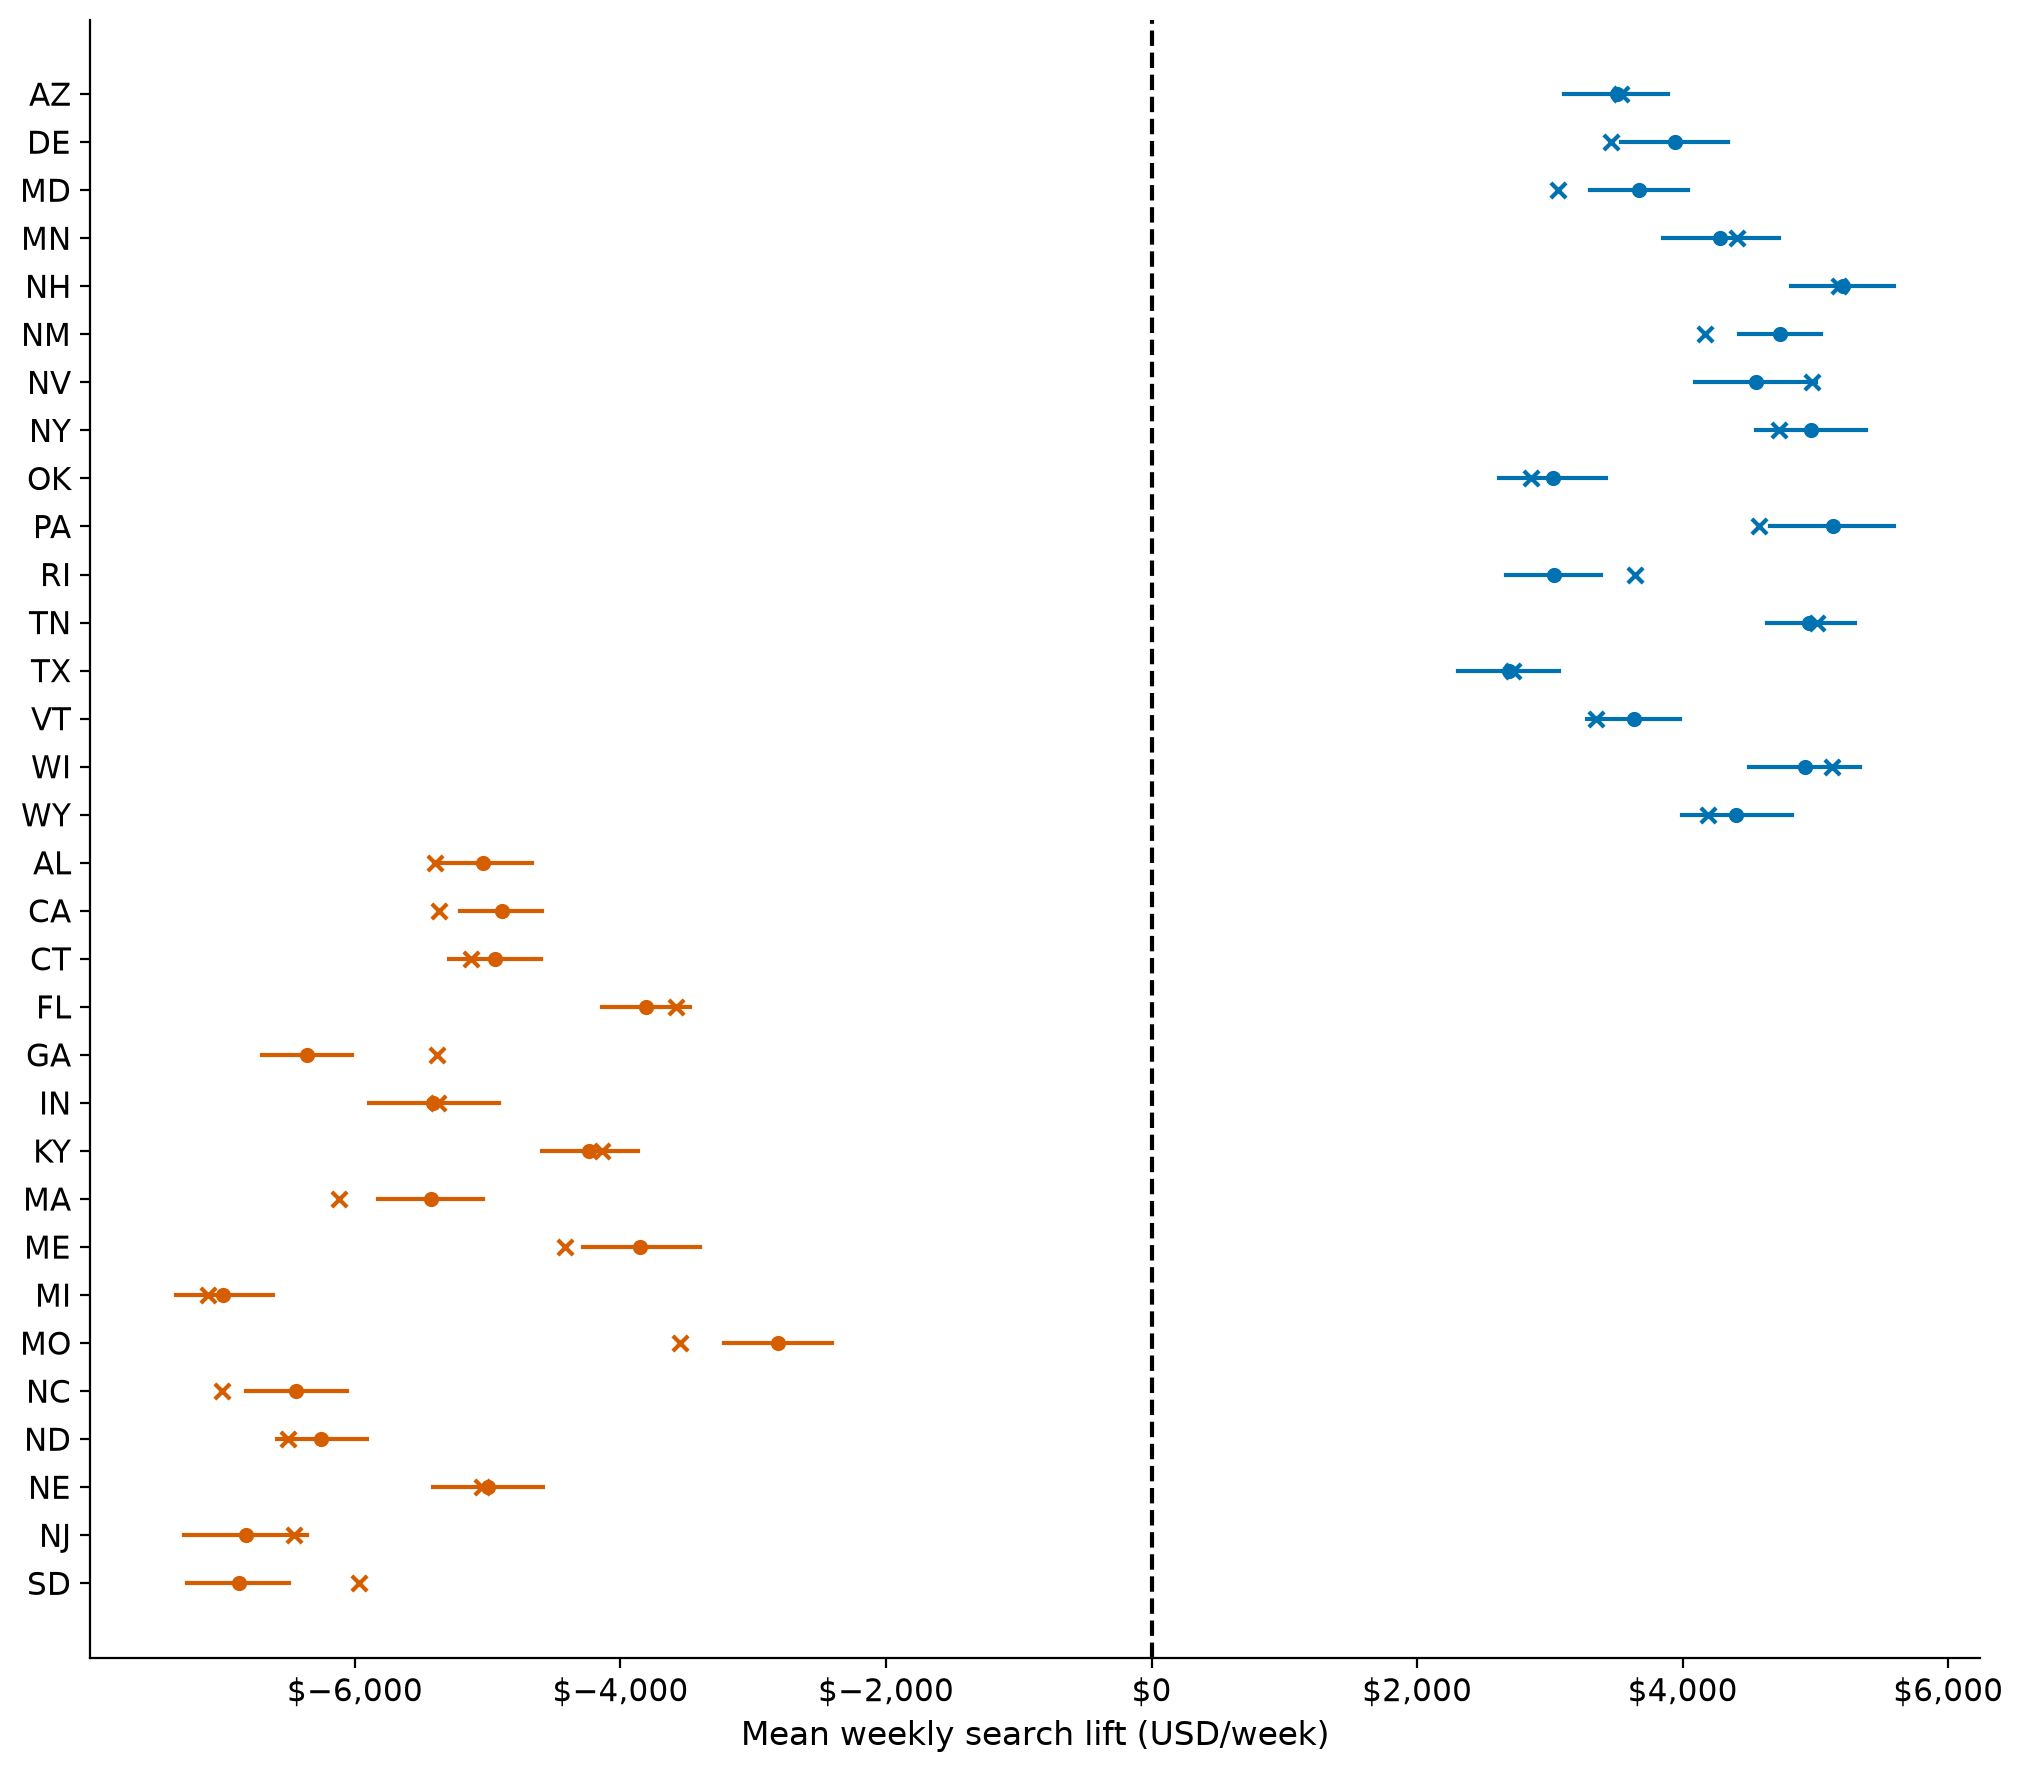

,coverage,mean_truth
arm,,
down,0.5625,-5408.201151
up,0.6875,4061.085858


In [10]:
summaries = result.arm_effect_table(
    start=experiment_start, end=experiment_end, aggregate="mean"
)
display(
    summaries.query("level == 'arm'")[["arm", "mean", "sd", "lower_94", "upper_94"]]
    .rename(
        columns={
            "mean": "Mean (USD/week/geo)",
            "sd": "Posterior SD",
            "lower_94": "94% ETI lower",
            "upper_94": "94% ETI upper",
        }
    )
    .round(1)
)
geo_effects = summaries.query("level == 'geo'").set_index("geo").loc[lift_rows.geo]
geo_effects["truth"] = true_lift.reindex(geo_effects.index)
geo_effects["covered"] = (geo_effects.truth >= geo_effects.lower_94) & (
    geo_effects.truth <= geo_effects.upper_94
)
fig, ax = plt.subplots(figsize=(FIG_WIDTH, FIG_HEIGHT * 2.5))
for i, (_g, row) in enumerate(geo_effects.iterrows()):
    color = ARM_COLORS[row.arm]
    ax.plot([row.lower_94, row.upper_94], [i, i], color=color)
    ax.scatter(row["mean"], i, color=color, s=20)
    ax.scatter(row.truth, i, color=color, marker="x", s=30)
ax.set_yticks(range(len(geo_effects)), geo_effects.index)
ax.invert_yaxis()
ax.axvline(0, color="black", linestyle="--")
ax.xaxis.set_major_formatter(USD)
ax.set_xlabel("Mean weekly search lift (USD/week)")
plt.show()
display(
    geo_effects.groupby("arm").agg(
        coverage=("covered", "mean"), mean_truth=("truth", "mean")
    )
)

**Caption:** Estimated mean weekly lift (dots), 94% ETIs (segments), and conditional-mean simulation truth (crosses) for all 32 treated markets, ordered by arm. Arm summaries average aligned draws over the same eight-week window and across the 16 geos in each arm; they are not additional calibration rows.

Coverage in this single simulation is a diagnostic, not a population coverage guarantee. Counterfactual errors can remain even when the intervention sign is clear.

In this run, only 20 of 32 known mean effects lie inside their nominal 94% ETIs. The stock impact draws condition on observed treated and donor outcomes; they do not represent all repeated-outcome and counterfactual uncertainty. Treat the exported SDs and resulting calibration precision as a conditional approximation, not a validated uncertainty model for a real experiment.

In [11]:
effect_draws = result.aggregate_draws(
    start=experiment_start, end=experiment_end, aggregate="mean"
)["geo"].sel(treated_units=lift_rows.geo.tolist())
effect_matrix = (
    effect_draws.stack(sample=("chain", "draw"))
    .transpose("treated_units", "sample")
    .values
)
effect_correlations = np.corrcoef(effect_matrix)
off_diagonal = effect_correlations[np.triu_indices(len(lift_rows), 1)]
effect_skewness = pd.DataFrame(effect_matrix.T).skew()
display(
    pd.Series(
        {
            "Median absolute off-diagonal correlation": np.median(np.abs(off_diagonal)),
            "Maximum absolute off-diagonal correlation": np.max(np.abs(off_diagonal)),
            "Maximum absolute marginal skewness": np.abs(effect_skewness).max(),
        }
    )
)

Median absolute off-diagonal correlation     0.014583
Maximum absolute off-diagonal correlation    0.068089
Maximum absolute marginal skewness           0.151385
dtype: float64

The rowwise likelihood below keeps marginal means and SDs and discards cross-geo covariance and non-Gaussian shape:

$$
\widehat{\Delta y_g}\sim\operatorname{Normal}\!\left(f_g(x_g+\Delta x_g)-f_g(x_g),\sigma_g\right).
$$

This is a **two-stage marginal-summary approximation**, not a full joint causal/MMM likelihood. The stock fit conditions on the observed controls and has geo-specific parameters. Small sampled correlations do not establish independence of real-world uncertainty, including shared donor shocks and counterfactual-model error. Strong dependence or skew calls for investigation before claiming precision; a covariance-aware extension is outside this example.

## Fit matched hierarchical MMMs

Each geo/channel gets a logistic `lam` and `beta`, partially pooled through channel-level distributions. Shared seasonality coefficients and fixed input/output scales match the simulation. The arm label remains provenance metadata, not an MMM dimension. There is one response curve per geo/channel, and every treated geo supplies only one finite-difference constraint.

Response-parameter tradeoffs can slow MCMC even with some independent historical variation. Both MMMs use [Nutpie low-rank adaptation](https://pymc-devs.github.io/nutpie/sampling-options.html) and 2,000 tuning plus 2,000 retained draws per chain. This experimental adaptation captures posterior correlations; check its diagnostics rather than assuming it solves identification. CausalPy retains its 1,000-draw configuration.

In [12]:
def make_mmm():
    saturation_priors = {
        "lam": Prior(
            "Normal",
            transform="exp",
            mu=Prior(
                "Normal",
                mu=xr.DataArray(
                    np.log([4.0, 3.0]), dims="channel", coords={"channel": channels}
                ),
                sigma=0.5,
                dims="channel",
            ),
            sigma=Prior("HalfNormal", sigma=0.3, dims="channel"),
            dims=("geo", "channel"),
            centered=False,
        ),
        "beta": Prior(
            "Normal",
            transform="exp",
            mu=Prior(
                "Normal",
                mu=xr.DataArray(
                    np.log([0.6, 0.5]), dims="channel", coords={"channel": channels}
                ),
                sigma=0.5,
                dims="channel",
            ),
            sigma=Prior("HalfNormal", sigma=0.3, dims="channel"),
            dims=("geo", "channel"),
            centered=False,
        ),
    }
    return MMM(
        date_column="date",
        target_column="revenue",
        channel_columns=channels,
        dims=("geo",),
        control_columns=["annual_sin", "annual_cos"],
        adstock=NoAdstock(l_max=1),
        saturation=LogisticSaturation(priors=saturation_priors),
        scaling=Scaling(
            channel=FixedScaling(dims=(), value=SCALE),
            target=FixedScaling(dims=(), value=SCALE),
        ),
        model_config={
            "intercept": Prior("Normal", mu=0.6, sigma=0.4, dims="geo"),
            "gamma_control": Prior("Normal", mu=0, sigma=0.1, dims="control"),
            "likelihood": Prior(
                "Normal", sigma=Prior("HalfNormal", sigma=0.03, dims="geo")
            ),
        },
    )

In [13]:
# Verify the direct simulator against the library model at the fixed truths.
truth_mmm = make_mmm()
X_baseline = long_features(baseline, estimation_dates, season_controls[104:])
X_realized = long_features(realized, estimation_dates, season_controls[104:])
truth_predictions = []
for features in (X_baseline, X_realized):
    truth_mmm.build_model(features, pd.Series(np.ones(len(features))))
    fixed = pm.do(
        truth_mmm.model,
        {
            "saturation_lam": true_lam,
            "saturation_beta": true_beta,
            "intercept_contribution": true_intercept,
            "gamma_control": true_gamma,
        },
    )
    truth_predictions.append(
        pm.draw(fixed["mu"].transpose("date", "geo"), random_seed=SEED) * SCALE
    )
np.testing.assert_allclose(truth_predictions[0], mu_baseline, rtol=1e-10)
np.testing.assert_allclose(truth_predictions[1], mu_experiment, rtol=1e-10)
np.testing.assert_allclose(
    (truth_predictions[1] - truth_predictions[0])[32:].mean(axis=0),
    true_lift,
    atol=1e-8,
)
del truth_mmm
print("Fixed-truth MMM means and signed contrasts agree with the simulator.")

Fixed-truth MMM means and signed contrasts agree with the simulator.


The numerical check verifies scales, channel composition, seasonality, and both contrast signs. Neither true effects nor the reserved experiment outcomes are supplied to the ordinary MMM target likelihood.

In [14]:
mmm_uncalibrated = make_mmm()
idata_uncalibrated = mmm_uncalibrated.fit(X_train, y_train, **mmm_fit_kwargs)

Output()

/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.


In [15]:
mmm_calibrated = make_mmm()  # Fresh model with the same priors and training data.
mmm_calibrated.build_model(X_train, y_train)
mmm_calibrated.add_lift_test_measurements(
    lift_rows,
    likelihood=Prior("Normal"),
    name="multi_arm_geo_lift",
)
np.testing.assert_equal(mmm_calibrated.model["multi_arm_geo_lift"].eval().size, 32)
idata_calibrated = mmm_calibrated.fit(X_train, y_train, **mmm_fit_kwargs)

Output()

/Users/benjamv/.codex/worktrees/multi-arm-geolift-calibration/pymc-marketing/.scratch/venv313/lib/python3.13/site-packages/pymc/sampling/deterministic.py:143: FutureWarning: `merge_dataset` is deprecated and will be removed in a future release. Use `extend_dataset=True` to add the deterministics to the original dataset, passing a `.copy()` of it if it should not be mutated.


Build once, attach calibration, then fit. Rebuilding after attachment would discard the calibration graph. One signed Normal observation per geo preserves both directions; collapsing active arms into a near-zero row would erase the information. `arm`, window, and unit columns are provenance, while only the geo/channel coordinates index the MMM.

Keep the exported table with its arm, window, and unit metadata alongside any saved model. MMM persistence retains the six columns consumed by the likelihood, so the full exporter table is the provenance record.

In [16]:
def diagnostic_row(label, draws, sample_stats):
    rhat = az.rhat(draws).to_array().values
    ess = az.ess(draws).to_array().values
    return {
        "fit": label,
        "divergences": int(sample_stats.diverging.sum()),
        "max_rhat": float(np.nanmax(rhat)),
        "min_ess": float(np.nanmin(ess)),
    }


diag = [
    diagnostic_row(
        "CausalPy mean effects",
        effect_draws.to_dataset(name="effect"),
        result.model.idata.sample_stats,
    )
]
for label, idata in [
    ("Uncalibrated MMM", idata_uncalibrated),
    ("Calibrated MMM", idata_calibrated),
]:
    diag.append(
        diagnostic_row(
            label,
            xr.Dataset(
                {
                    var: idata.posterior[var]
                    for var in [
                        "saturation_lam",
                        "saturation_beta",
                        "gamma_control",
                        "intercept_contribution",
                    ]
                }
            ),
            idata.sample_stats,
        )
    )
display(
    pd.DataFrame(diag)
    .set_index("fit")
    .style.format({"max_rhat": "{:.4f}", "min_ess": "{:,.0f}"})
)

,divergences,max_rhat,min_ess
fit,,,
CausalPy mean effects,0,1.0052,"1,541"
Uncalibrated MMM,0,1.0107,197
Calibrated MMM,0,1.0109,159


Inspect divergences, R-hat, and effective sample size before interpreting the comparisons. Targets are zero divergences, R-hat ≤ 1.01, and approximately 400 effective draws for central quantities. These diagnostics assess sampling, not the validity of the counterfactual or pooling assumptions.

Individual saturation parameters can mix more slowly than their implied response curves. Inspect both diagnostic tables: longer runs are needed before interpreting individual amplitudes or curvature parameters when their diagnostics miss these targets. The comparisons below concern sampled response curves.

This run has zero divergences. The central-curve R-hat values below are under 1.005, but the calibrated minimum ESS is about 282, below the 400-draw target. Individual parameters also fall short (maximum R-hat about 1.011 and minimum ESS about 159). Treat the displayed curves as an illustrative posterior comparison; longer runs are needed for more precise Monte Carlo summaries.

## What changed in the response estimates?

Compare model-implied signed lifts in original outcome units. The calibrated model exposes `multi_arm_geo_lift_model_estimated_lift_original_scale`; the uncalibrated model's contrast is evaluated at the same geo-specific spend points.

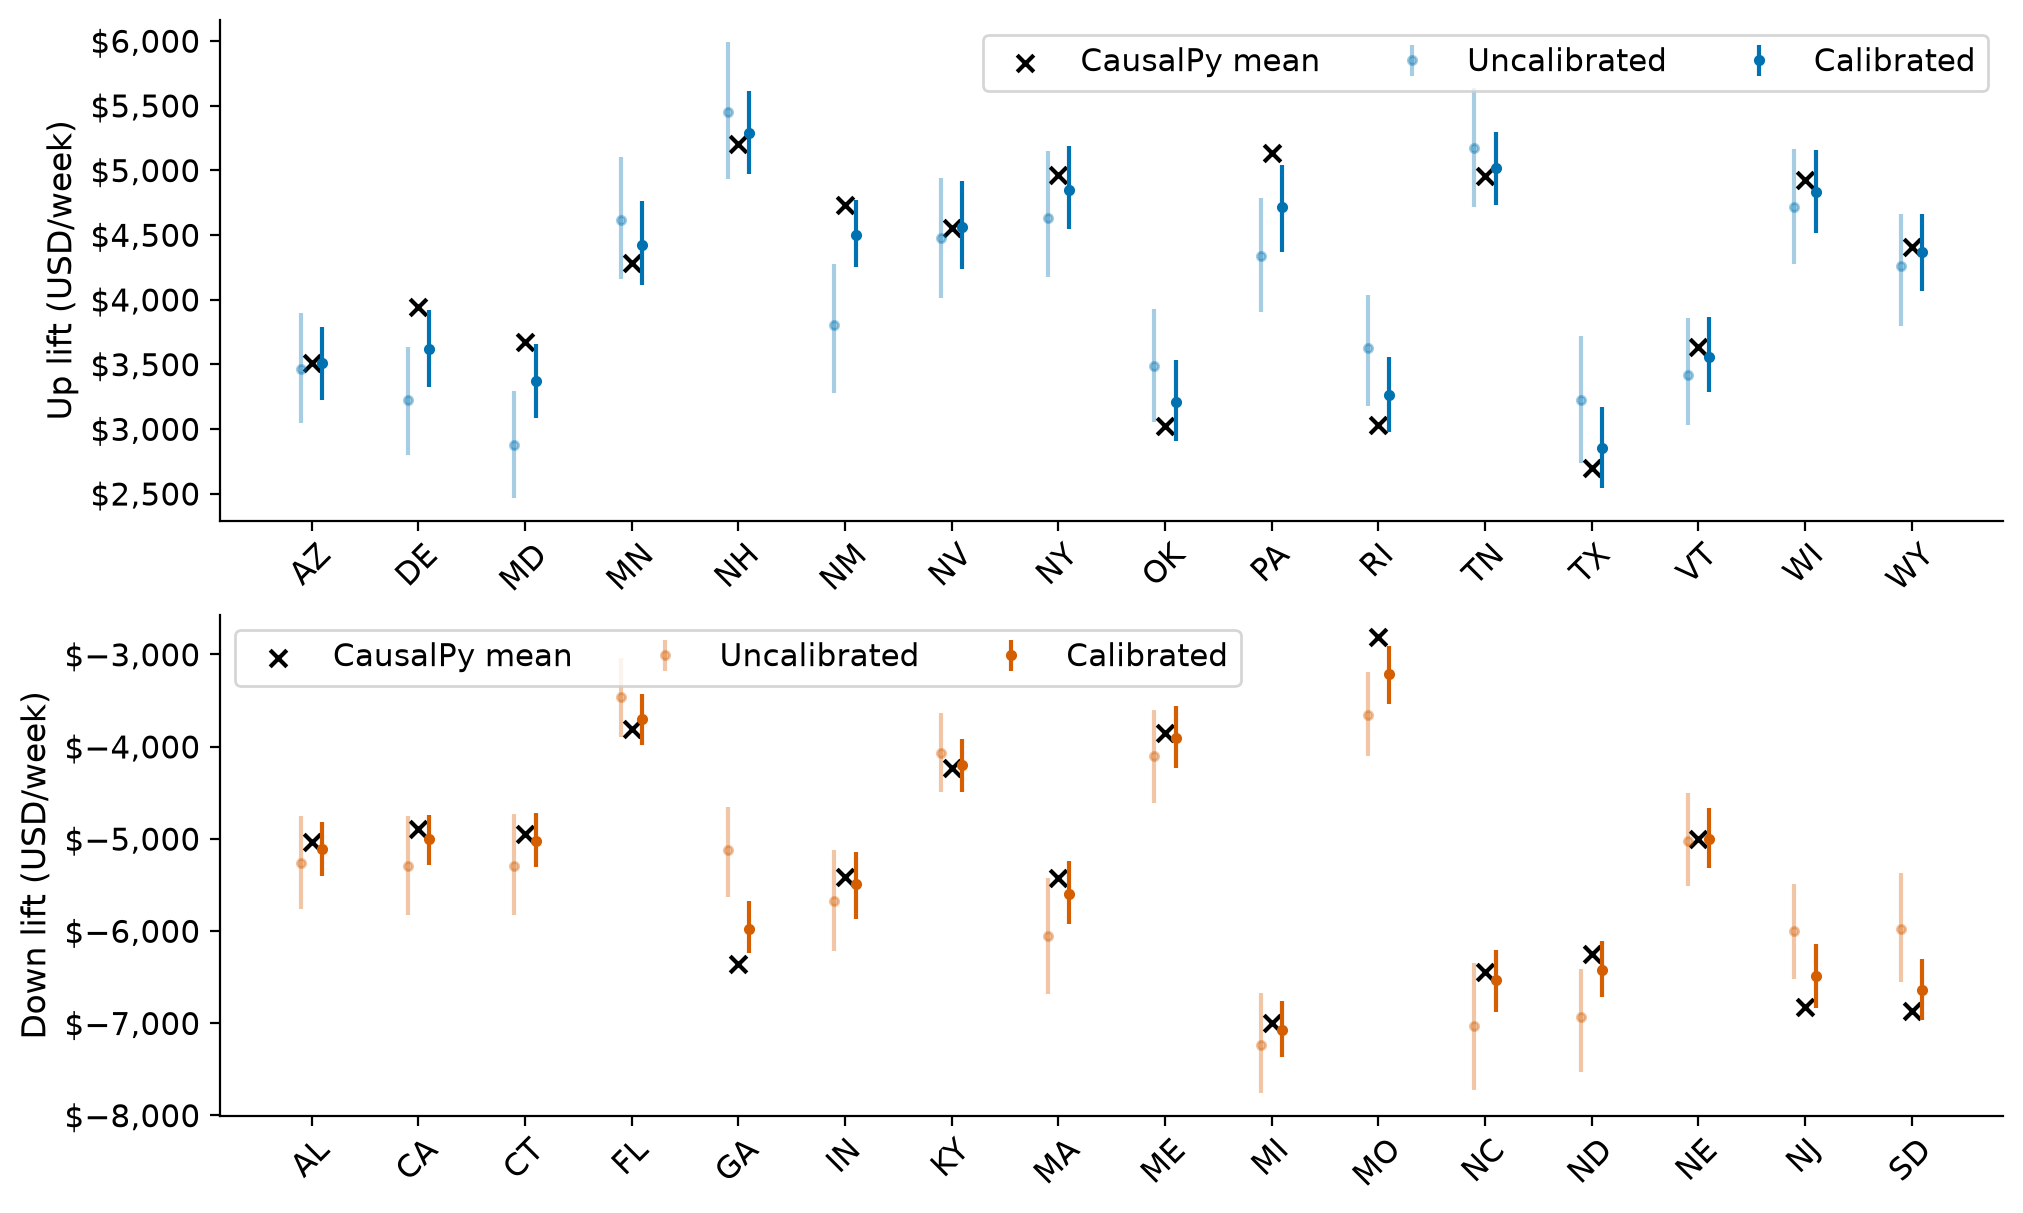

In [17]:
def posterior_lifts(idata):
    posterior = idata.posterior
    values = []
    for row in lift_rows.itertuples():
        lam = posterior.saturation_lam.sel(geo=row.geo, channel=row.channel)
        beta = posterior.saturation_beta.sel(geo=row.geo, channel=row.channel)
        values.append(
            SCALE
            * beta
            * (
                np.tanh(lam * (row.x + row.delta_x) / SCALE / 2)
                - np.tanh(lam * row.x / SCALE / 2)
            )
        )
    return xr.concat(values, dim=pd.Index(lift_rows.geo, name="lift_geo"))


lifts_uncalibrated = posterior_lifts(idata_uncalibrated)
lifts_calibrated = posterior_lifts(idata_calibrated)
registered_lift = idata_calibrated.posterior[
    "multi_arm_geo_lift_model_estimated_lift_original_scale"
]
np.testing.assert_allclose(
    registered_lift.transpose("chain", "draw", ...).values,
    lifts_calibrated.transpose("chain", "draw", "lift_geo").values,
)
fig, axes = plt.subplots(2, 1, figsize=(FIG_WIDTH, FIG_HEIGHT * 1.7), sharex=False)
for ax, arm in zip(axes, ["up", "down"], strict=True):
    members = lift_rows.query("arm == @arm")
    positions = np.arange(len(members))
    for j, (draws, label, alpha) in enumerate(
        [
            (lifts_uncalibrated, "Uncalibrated", 0.35),
            (lifts_calibrated, "Calibrated", 1.0),
        ]
    ):
        selected = draws.sel(lift_geo=members.geo.tolist())
        hdi = az.hdi(selected, prob=0.94)
        ax.errorbar(
            positions + (j - 0.5) * 0.2,
            selected.mean(["chain", "draw"]),
            yerr=np.abs(
                hdi.transpose("ci_bound", "lift_geo").values
                - selected.mean(["chain", "draw"]).values
            ),
            fmt="o",
            color=ARM_COLORS[arm],
            alpha=alpha,
            label=label,
            markersize=3,
        )
    ax.scatter(
        positions, members.delta_y, marker="x", color="black", label="CausalPy mean"
    )
    ax.set_xticks(positions, members.geo, rotation=45)
    ax.set_ylabel(f"{arm.title()} lift (USD/week)")
    ax.yaxis.set_major_formatter(USD)
    ax.legend(fontsize=11, ncol=3)
plt.show()

**Caption:** Original-unit MMM-implied weekly lift with 94% HDIs before and after calibration; black crosses are the CausalPy means. Each panel contains one intervention direction. Agreement is expected after adding these observations and is not independent validation.

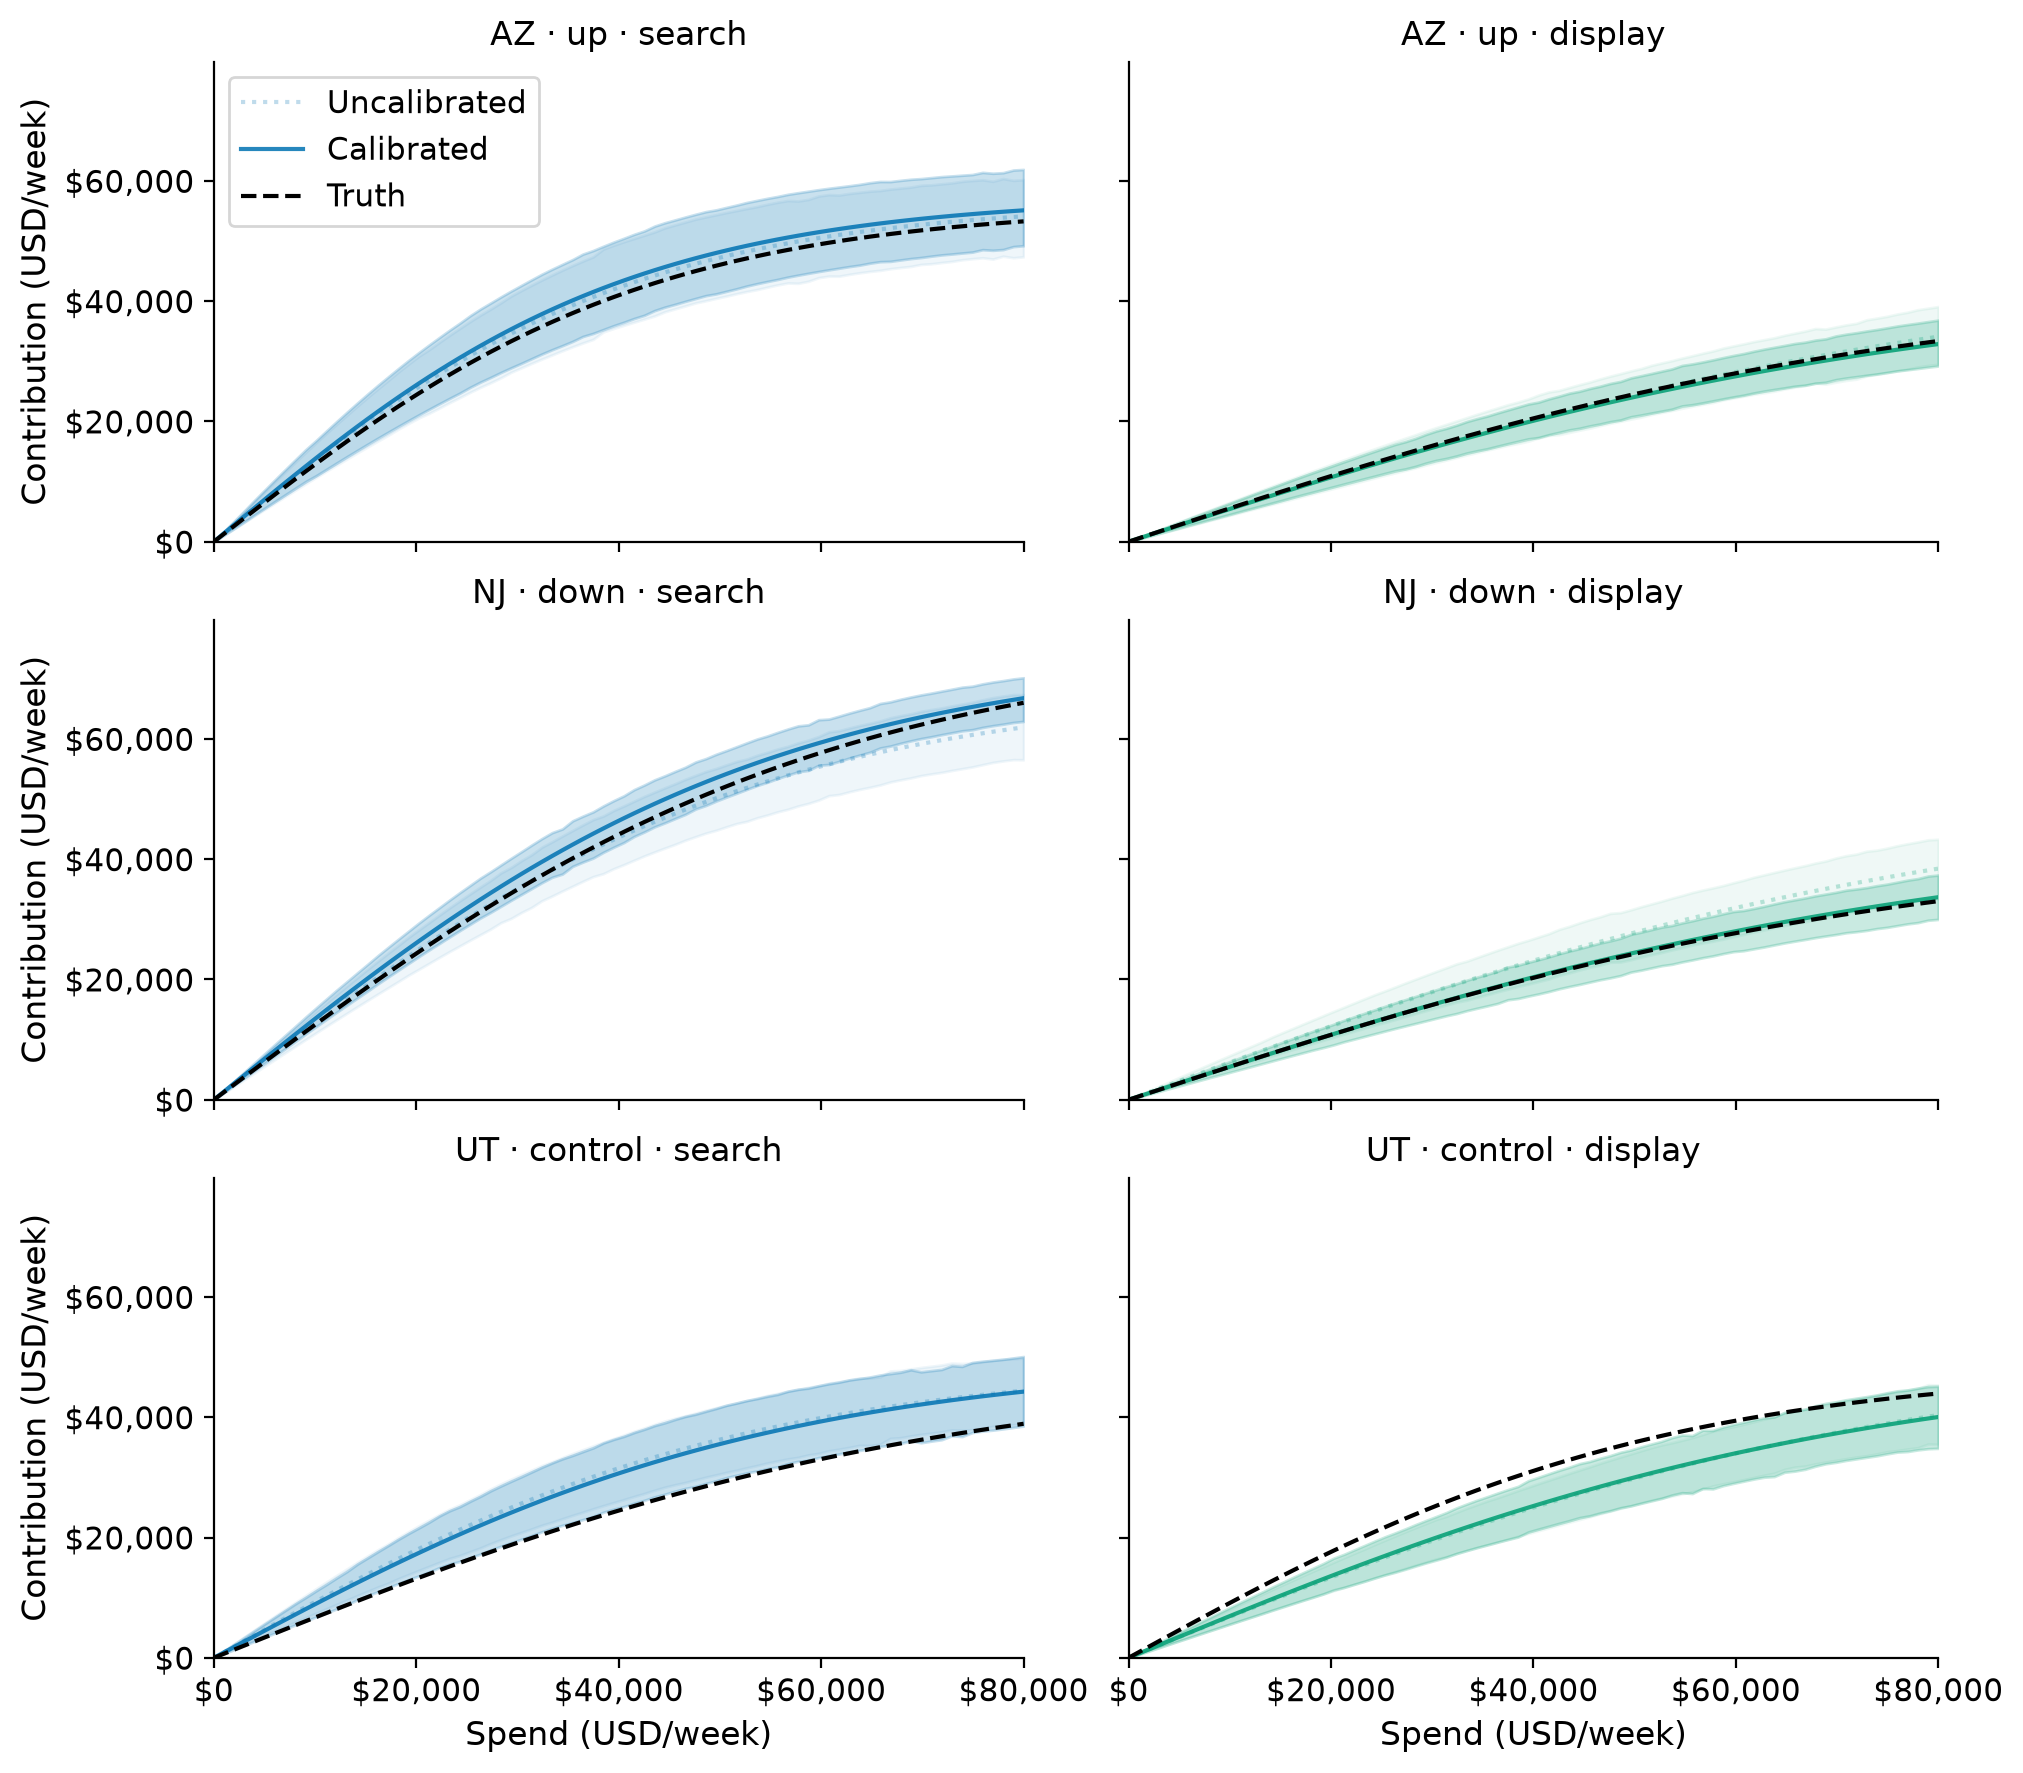

In [18]:
spend_grid = np.linspace(0, 80_000, 80)


def response_draws(idata):
    p = idata.posterior
    spend = xr.DataArray(spend_grid / SCALE, dims="spend", coords={"spend": spend_grid})
    return SCALE * p.saturation_beta * np.tanh(p.saturation_lam * spend / 2)


curve_draws = {
    "Uncalibrated": response_draws(idata_uncalibrated),
    "Calibrated": response_draws(idata_calibrated),
}
posterior_upper = max(
    float(
        az.hdi(draws.sel(geo=list(representatives.values())), prob=0.94)
        .sel(ci_bound="upper")
        .max()
    )
    for draws in curve_draws.values()
)
truth_upper = SCALE * true_beta[[geos.index(g) for g in representatives.values()]].max()
curve_upper = 1.05 * max(posterior_upper, truth_upper)
fig, axes = plt.subplots(
    3, 2, figsize=(FIG_WIDTH, FIG_HEIGHT * 2.5), sharex=True, sharey=True
)
for row, arm in enumerate(["up", "down", "control"]):
    g = representatives[arm]
    for col, channel in enumerate(channels):
        ax = axes[row, col]
        for label, alpha, style in [
            ("Uncalibrated", 0.25, ":"),
            ("Calibrated", 0.85, "-"),
        ]:
            draws = curve_draws[label].sel(geo=g, channel=channel)
            hdi = az.hdi(draws, prob=0.94)
            ax.fill_between(
                spend_grid,
                hdi.sel(ci_bound="lower"),
                hdi.sel(ci_bound="upper"),
                color=CHANNEL_COLORS[channel],
                alpha=alpha * 0.25,
            )
            ax.plot(
                spend_grid,
                draws.mean(["chain", "draw"]),
                color=CHANNEL_COLORS[channel],
                alpha=alpha,
                linestyle=style,
                label=label,
            )
        i, c = geos.index(g), channels.index(channel)
        truth = (
            SCALE * true_beta[i, c] * np.tanh(true_lam[i, c] * spend_grid / SCALE / 2)
        )
        ax.plot(spend_grid, truth, color="black", linestyle="--", label="Truth")
        ax.set_title(f"{g} · {arm} · {channel}", fontsize=12)
        ax.xaxis.set_major_formatter(USD)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.yaxis.set_major_formatter(USD)
        ax.set(xlim=(0, 80_000), ylim=(0, curve_upper))
        if col == 0:
            ax.set_ylabel("Contribution (USD/week)")
        if row == 2:
            ax.set_xlabel("Spend (USD/week)")
axes[0, 0].legend(fontsize=11)
plt.show()

**Caption:** Posterior mean response curves and 94% HDI bands for predetermined up, down, and control representatives, in original units. Channel colors are constant across models; dotted/light curves are uncalibrated and solid/dark curves calibrated. Black dashed curves are known simulation truth.

In [19]:
metric_rows = []
for label, draws in curve_draws.items():
    hdi = az.hdi(draws, prob=0.94)
    for g in geos:
        i = geos.index(g)
        for channel in channels:
            c = channels.index(channel)
            selected = draws.sel(geo=g, channel=channel)
            truth = (
                SCALE
                * true_beta[i, c]
                * np.tanh(true_lam[i, c] * spend_grid / SCALE / 2)
            )
            bounds = hdi.sel(geo=g, channel=channel)
            metric_rows.append(
                {
                    "model": label,
                    "arm": geo_arm[g],
                    "channel": channel,
                    "MAE (USD/week)": float(
                        np.abs(selected.mean(["chain", "draw"]) - truth).mean()
                    ),
                    "HDI width (USD/week)": float(
                        (
                            bounds.sel(ci_bound="upper") - bounds.sel(ci_bound="lower")
                        ).mean()
                    ),
                    "Truth coverage": float(
                        (
                            (truth >= bounds.sel(ci_bound="lower"))
                            & (truth <= bounds.sel(ci_bound="upper"))
                        ).mean()
                    ),
                }
            )
curve_metrics = pd.DataFrame(metric_rows).groupby(["channel", "arm", "model"]).mean()
display(curve_metrics.round(2))
curve_diagnostics = []
for label, draws in curve_draws.items():
    central_curves = draws.sel(spend=spend_grid[[20, 40, 60]])
    curve_diagnostics.append(
        {
            "model": label,
            "curve max R-hat": float(az.rhat(central_curves).max()),
            "curve min ESS": float(az.ess(central_curves).min()),
        }
    )
display(pd.DataFrame(curve_diagnostics).round(4))
print(f"Total elapsed: {(time.perf_counter() - started) / 60:.1f} minutes")

MAE (USD/week)  HDI width (USD/week)  \
channel arm     model                                                
display control Calibrated           1780.45               7547.60   
                Uncalibrated         1850.31               7152.49   
        down    Calibrated           2062.44               5381.98   
                Uncalibrated         1579.22               7086.69   
        up      Calibrated           1844.70               6270.67   
                Uncalibrated         2072.36               7296.79   
search  control Calibrated           1869.16              10058.35   
                Uncalibrated         1878.33               9547.10   
        down    Calibrated           1967.39               7539.26   
                Uncalibrated         1915.52               9562.36   
        up      Calibrated           2114.94              10064.03   
                Uncalibrated         2266.93              10156.43   

                              Truth coverage  
channel arm     model                         
display control Calibrated              0.88  
                Uncalibrated            0.85  
        down    Calibrated              0.69  
                Uncalibrated            0.95  
        up      Calibrated              0.82  
                Uncalibrated            0.85  
search  control Calibrated              0.94  
                Uncalibrated            0.94  
        down    Calibrated              0.84  
                Uncalibrated            0.94  
        up      Calibrated              0.92  
                Uncalibrated            0.91

,model,curve max R-hat,curve min ESS
0,Uncalibrated,1.0034,724.5063
1,Calibrated,1.0047,282.4028


Total elapsed: 16.6 minutes


Curve error and interval width are averaged over the displayed 0–80,000 USD/week grid, then across geos within each arm. Coverage is the fraction of grid points whose truth lies in the pointwise 94% HDI. These summaries describe this simulation, including extrapolation beyond historical spend; they are not forecast scores or population bias estimates. Search is directly calibrated, while display and controls change only through the shared model and parameter tradeoffs.

The observed gain is modest and uneven. Some down-arm intervals narrow while truth coverage falls and curve error does not improve. Narrower conditional intervals are therefore not evidence of better recovery. The exported effect intervals already under-cover truth; ignored two-stage uncertainty can propagate through calibration. These results illustrate the integration and its limitations, rather than validating the exported SDs as real-world sampling errors.

## Summary and limitations

The workflow preserves each geo's signed contrast against its own baseline, exports weekly estimates and posterior SDs in original units, and attaches one combined table before fitting a fresh MMM. Controls and display remain unchanged; the MMM training outcomes are separate from the outcomes used to estimate lift. Equal delivered spend changes cancel financially, while nonlinear heterogeneous response means their outcomes need not cancel.

Both directions add information across the population, but every treated geo still supplies only one constraint on its own curve. Residual `lam`/`beta` and cross-channel tradeoffs remain. Partial pooling assumes exchangeable geo response parameters; control markets receive no direct lift observation. Precision gains rely on the marginal Normal approximation, the counterfactual fit, and the assumed common seasonality. Shared controls do not make real-world uncertainty independent.

No carryover, constant experiment baselines, an identity link, no spillovers, and a compatible simulator make this a deliberately simple scalar calibration example. Real adstock or unstable spend requires a compatible estimand and temporal treatment rather than substituting average spend into a nonlinear response. Do not infer guaranteed parameter recovery or predictive improvement.

Continue with {ref}`mmm_geolift_calibration`, {ref}`mmm_multidimensional_example`, and the [CausalPy exporter contract](https://causalpy.readthedocs.io/en/latest/api/generated/causalpy.experiments.up_down_geolift.UpDownGeoLift.to_mmm_lift.html).

In [20]:
%load_ext watermark
%watermark -n -u -v -iv -w -p pymc_marketing,causalpy,pytensor

Last updated: Wed, 14 Oct 2026

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.15.0

pymc_marketing: 1.2.0
causalpy      : 1.0.0rc1
pytensor      : 3.3.2

IPython       : 9.15.0
arviz         : 1.2.0
causalpy      : 1.0.0rc1
logging       : 0.5.1.2
matplotlib    : 3.11.1
numpy         : 2.4.6
pandas        : 3.0.5
pymc          : 6.3.2
pymc_extras   : 0.15.1
pymc_marketing: 1.2.0
pytensor      : 3.3.2
xarray        : 2026.4.0

Watermark: 2.6.0

